# Analiza i wizualizacja meczu euro 2020 Szwecja - Polska

## Pozyskanie danych event po evencie

In [1]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

merged_events.head(5)

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,1.422263,[b3c8e55c-581c-4c68-b722-446903bbd574],"{'recipient': {'id': 3702, 'name': 'Victor Nil...",3788776,790,5617.0,,,,
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,[9e9ec22a-f1cf-4460-ba53-c786f7b05287],,3788776,790,3702.0,,,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,1.150845,"[470d2435-f5a4-46f9-aa0c-af2ce5e92f31, b3c8e55...","{'end_location': [36.8, 41.1]}",3788776,790,3702.0,,,,
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,3.210068,[e7e53c4b-6ee1-4f04-9a41-c4d3906d072e],"{'recipient': {'id': 5612, 'name': 'Mikael Lus...",3788776,790,3702.0,,,,
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,[470d2435-f5a4-46f9-aa0c-af2ce5e92f31],,3788776,790,5612.0,,,,


## Ujednolicenie perspektywy lewa-prawa bramka

In [2]:
from dataframe_modify.generalize_perspective import generalize_perspective

merged_events = generalize_perspective(merged_events)

['Pass' 'Ball Receipt*' 'Carry' ... 'Pass' 'Half End' 'Half End']


## Dodanie stref boiska

In [3]:
from dataframe_modify.grid_areas import add_areas_and_pos

merged_events = add_areas_and_pos(merged_events)

merged_events['area_code']

0       F4D4
1         D4
2       D4D5
3       D5E7
4         E7
        ... 
2566      B8
2567    B8B7
2568    B7Z3
2569        
2570        
Name: area_code, Length: 2571, dtype: object

## Podział na sekwencje

In [4]:
from sequences.get_sequences import get_event_sequences

sequences = get_event_sequences(merged_events)

sequences[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,off_camera,counterpress,out,start_x,start_y,end_x,end_y,start_area,end_area,area_code
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,,,,60.0,40.0,36.1,39.7,F4,D4,F4D4
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,,,36.1,39.7,,,D4,,D4
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,,,,36.1,39.7,36.8,41.1,D4,D5,D4D5
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,,,,36.8,41.1,49.8,68.1,D5,E7,D5E7
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,,,49.8,68.1,,,E7,,E7
5,a3c476e1-a372-492d-bf5b-4ebe5a98d21c,10,1,00:00:05.863,0,5,Pass,2,Sweden,From Kick Off,...,,,,49.8,68.1,95.3,38.1,E7,J4,E7J4
6,2b8824d2-8f34-436b-9bce-f8960a0f9cbf,11,1,00:00:09.353,0,9,Ball Receipt*,2,Sweden,From Kick Off,...,,,,95.3,38.1,,,J4,,J4
7,baca1749-3f13-4fd4-8c1e-a84748f80a5d,12,1,00:00:09.353,0,9,Duel,2,Sweden,From Kick Off,...,,,,95.3,38.1,,,J4,,J4


## Narysowanie pierwszych 3 sekwencji

Sequence: 1
Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>
4: Robin Quaison (Duel) <00:00:09.353>


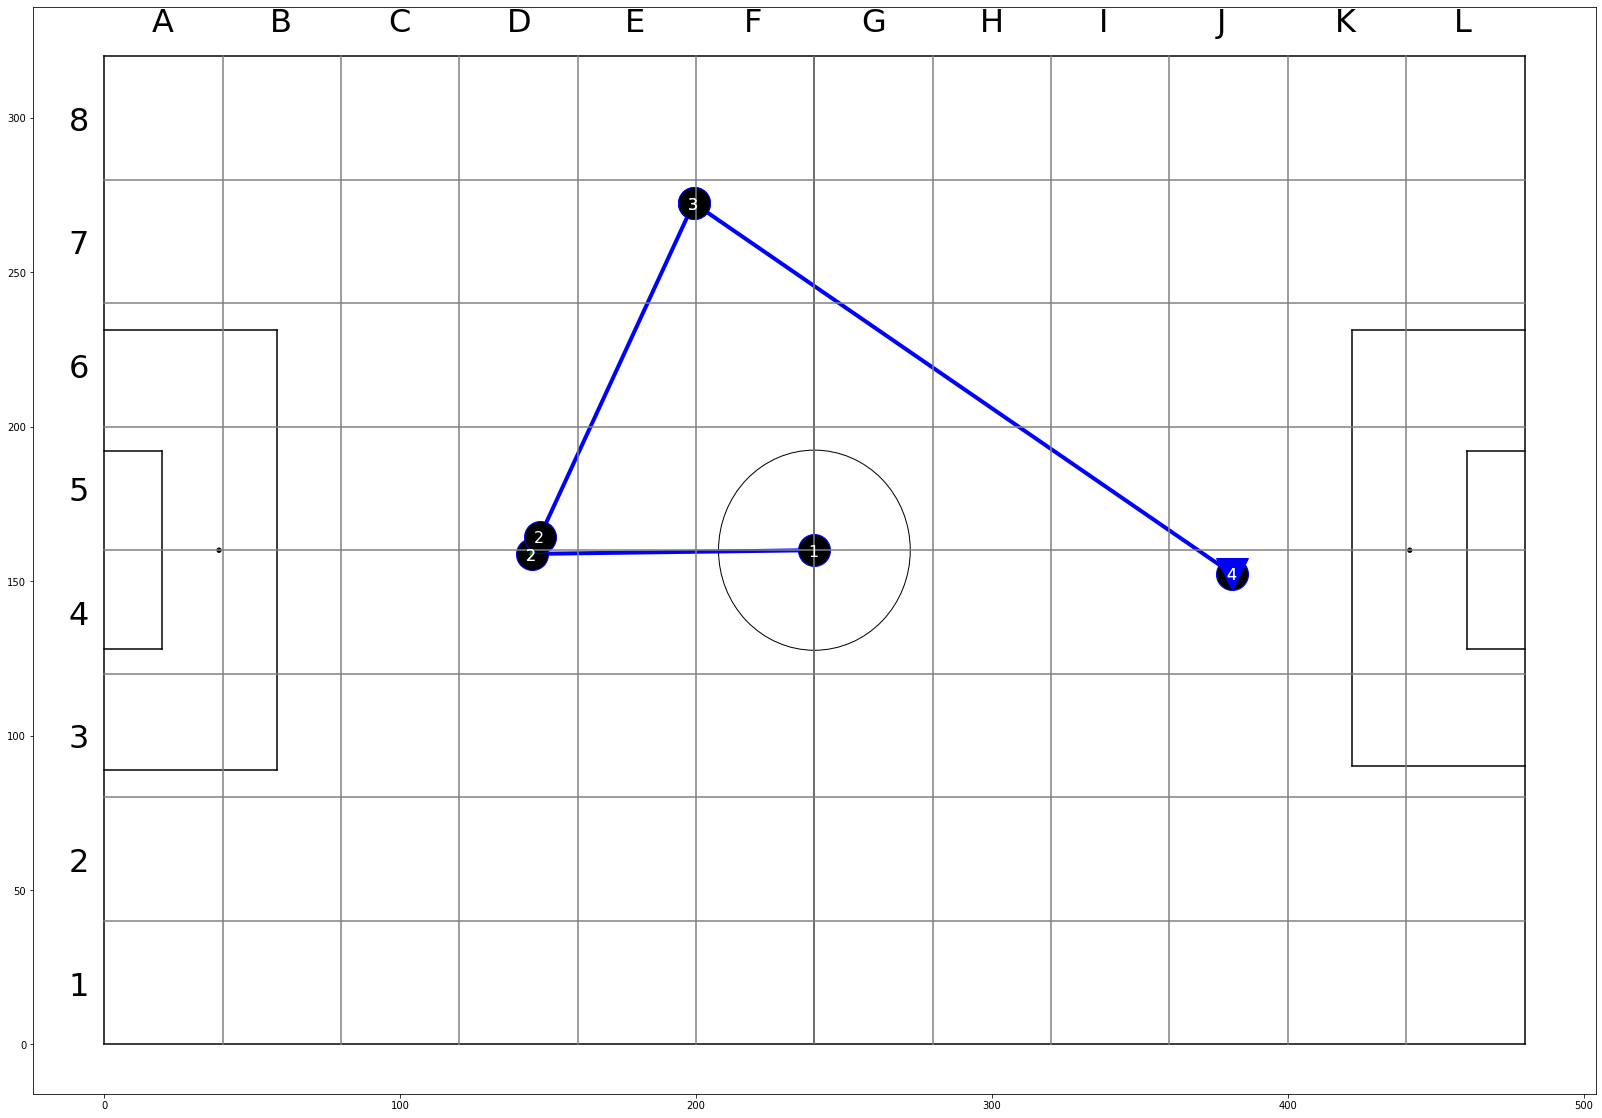

Sequence: 2
Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00

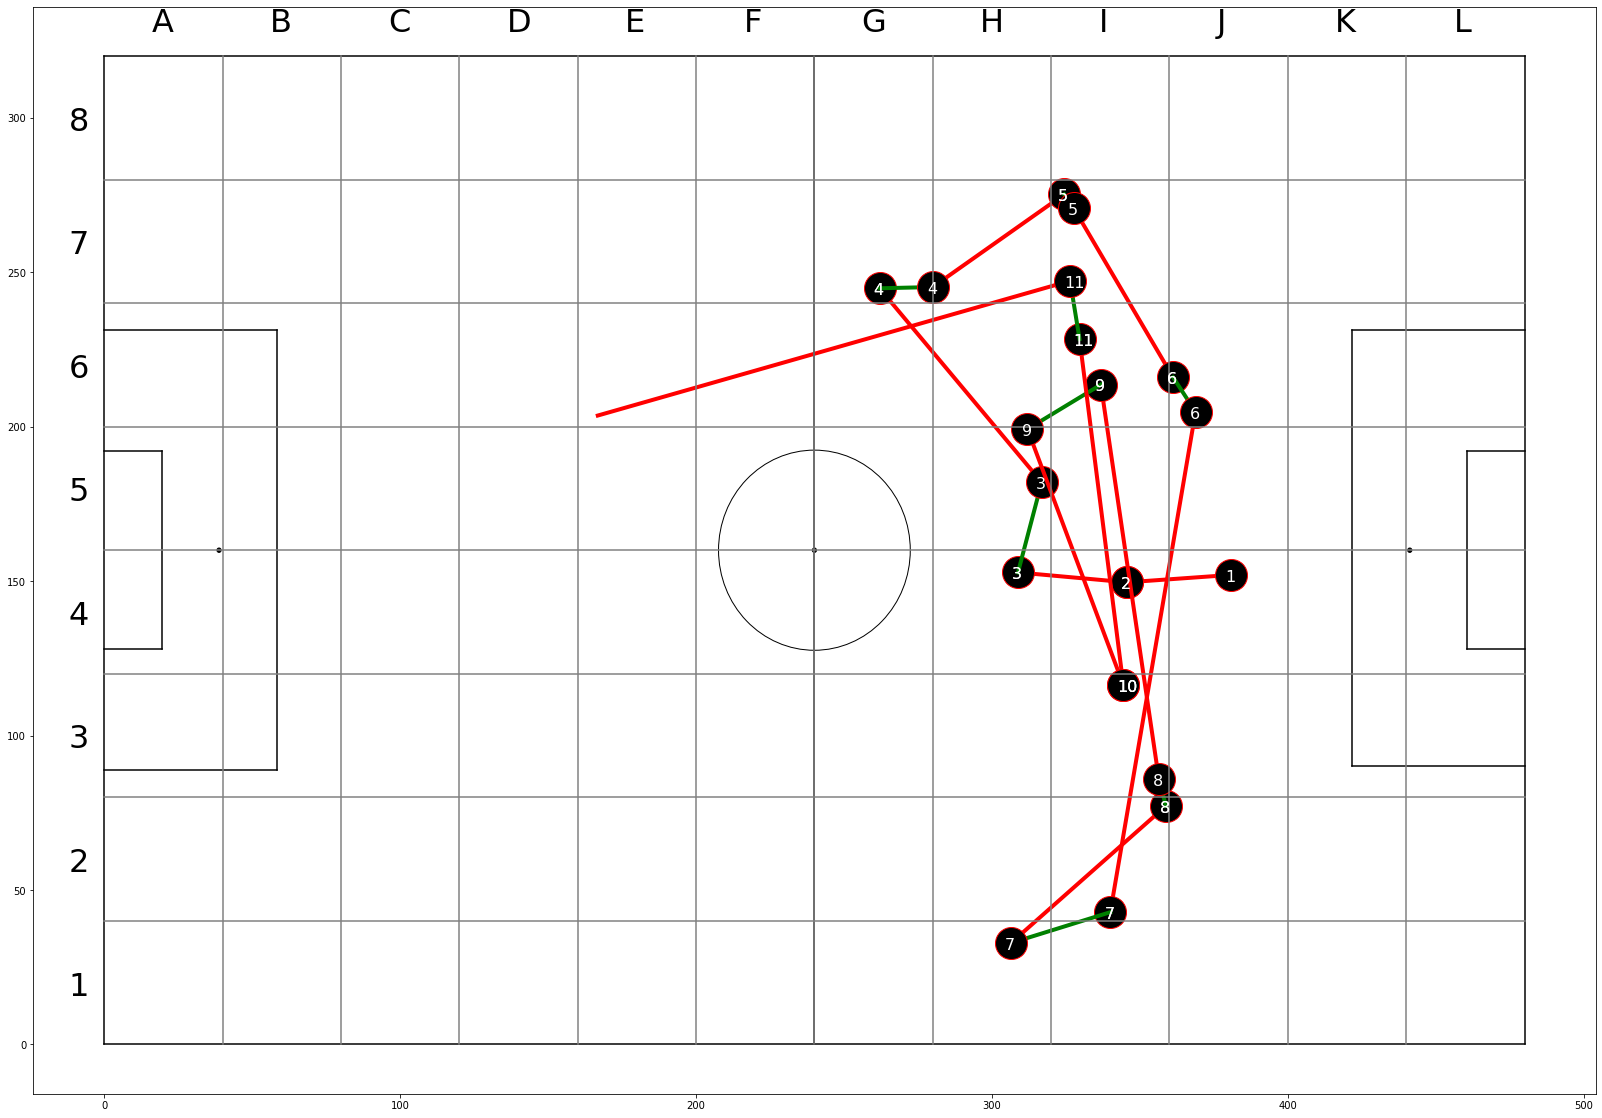

Sequence: 3
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


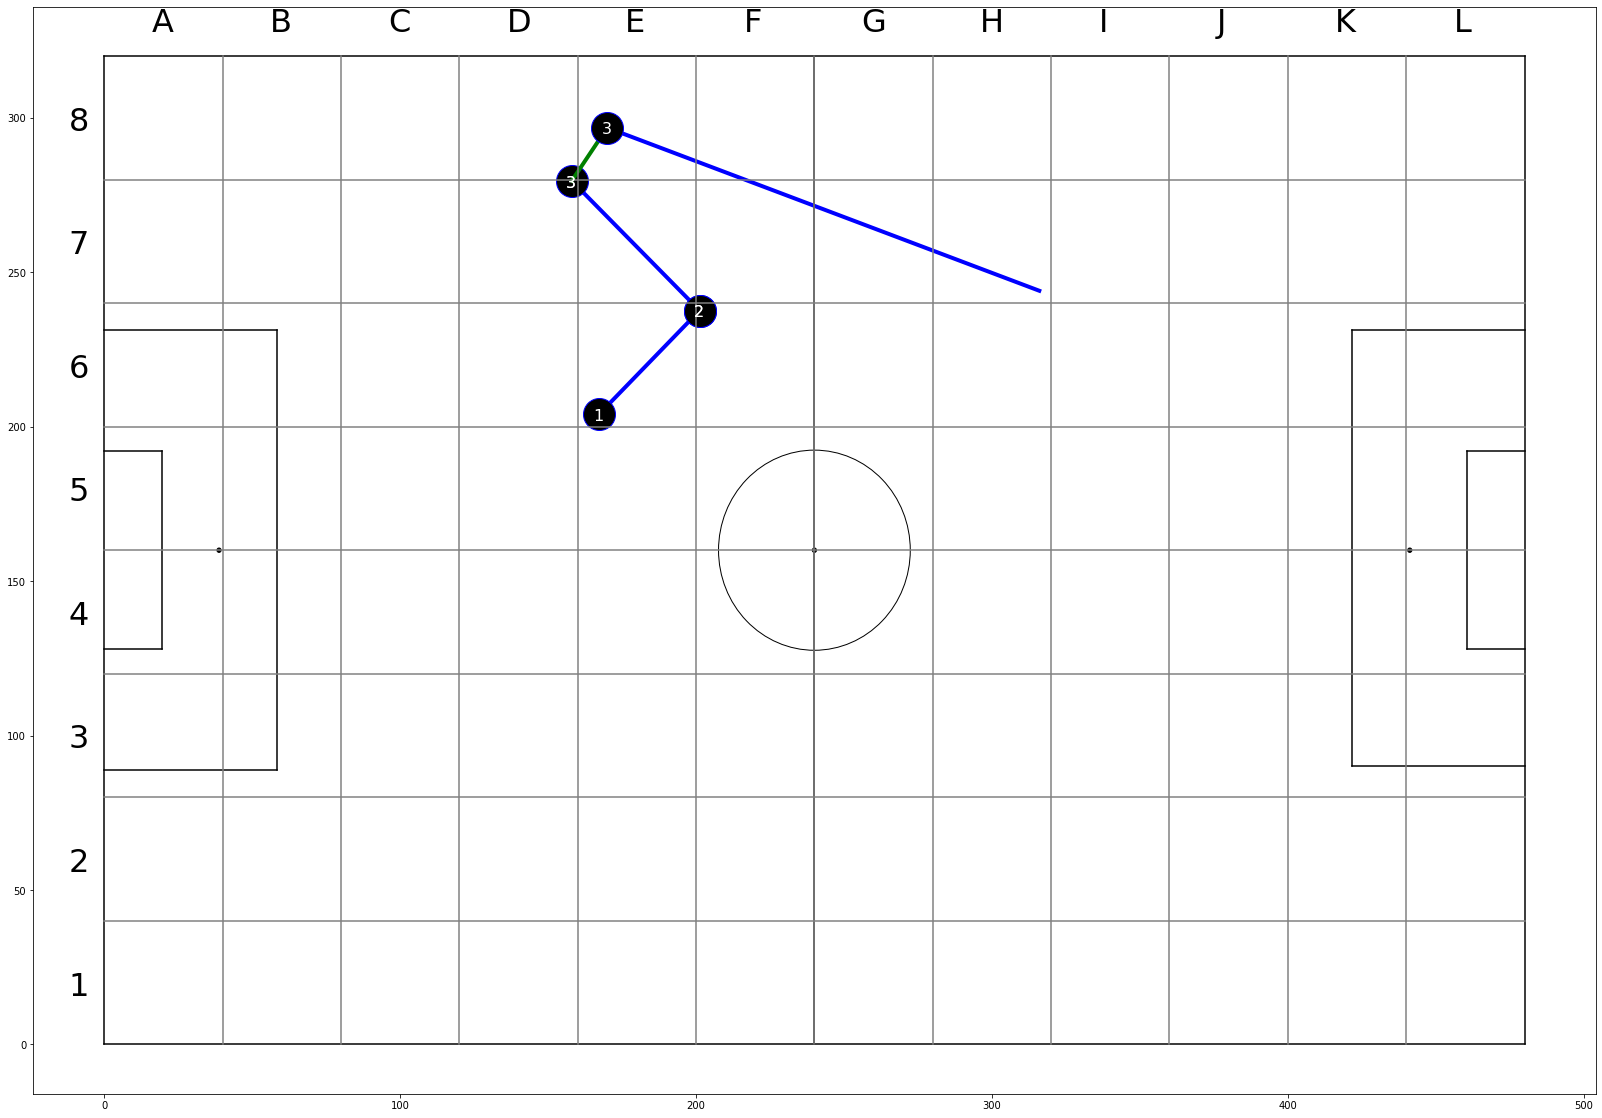

Sequence: 4
Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>
5: Mikael Lustig (Duel) <00:00:50.138>


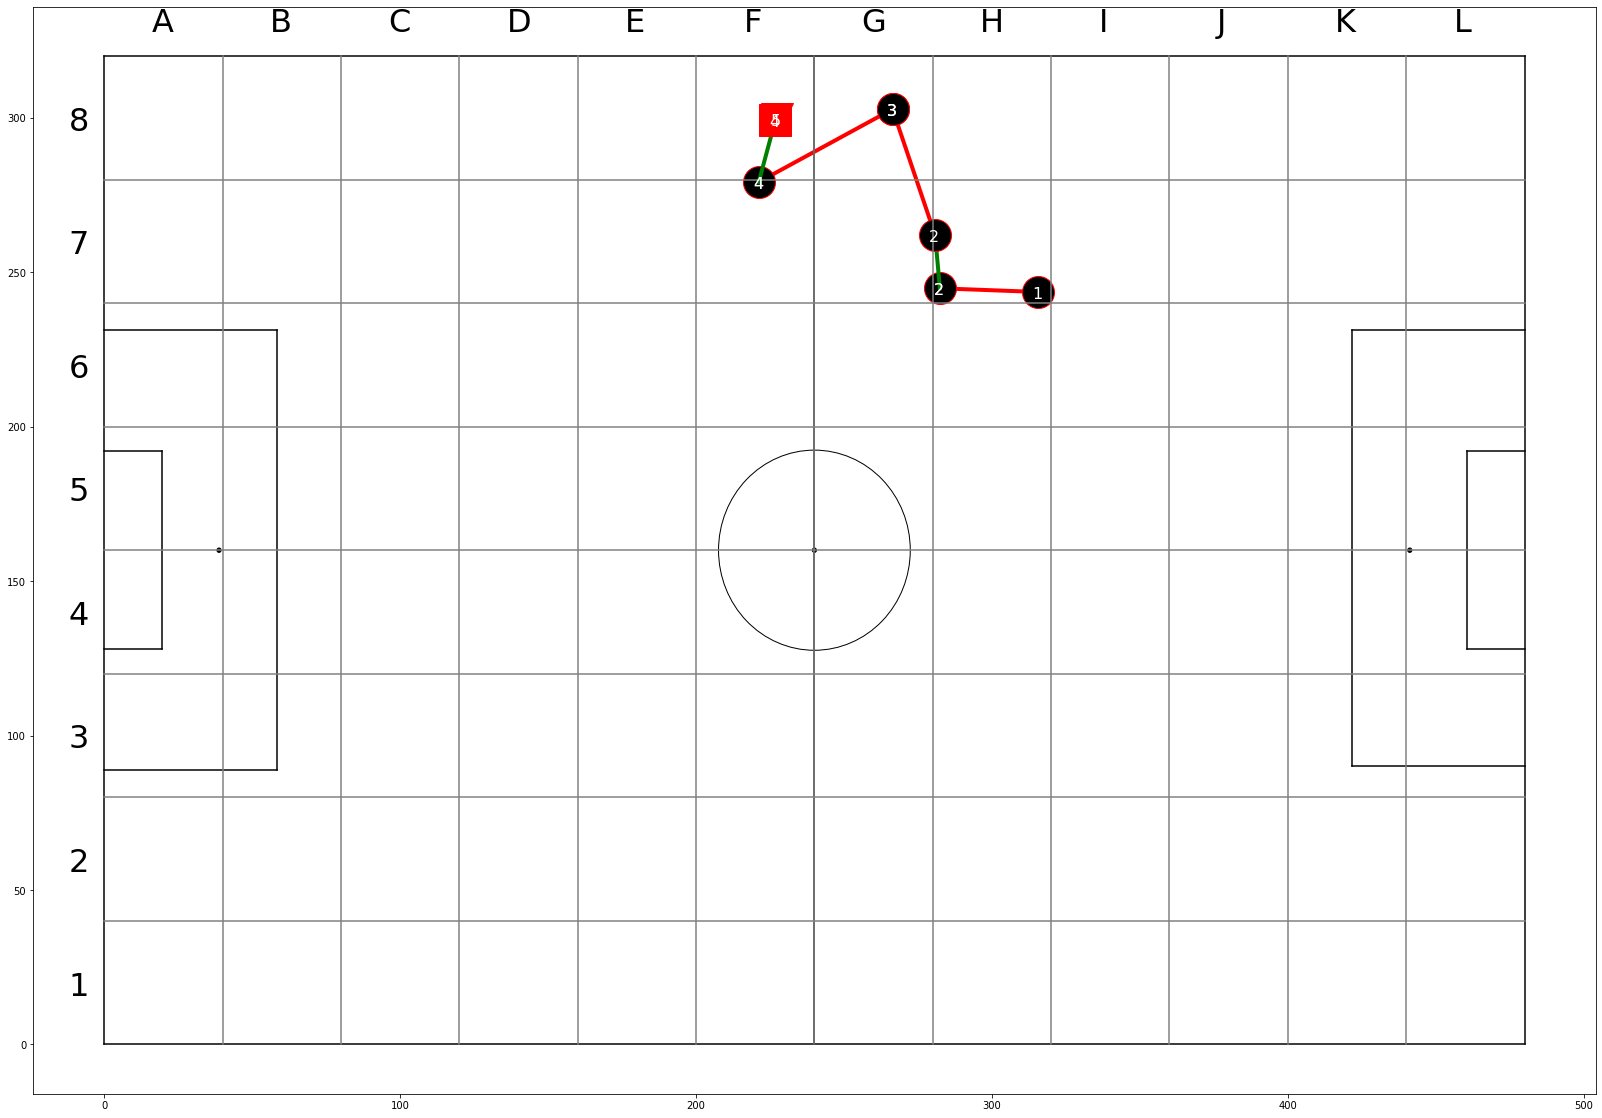

Sequence: 5
Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Kamil Glik (Duel) <00:01:19.168>
10: Emil Peter Forsberg (Pass) <00:01:19.483>
11: Alexander Isak (Ball Receipt*) <0

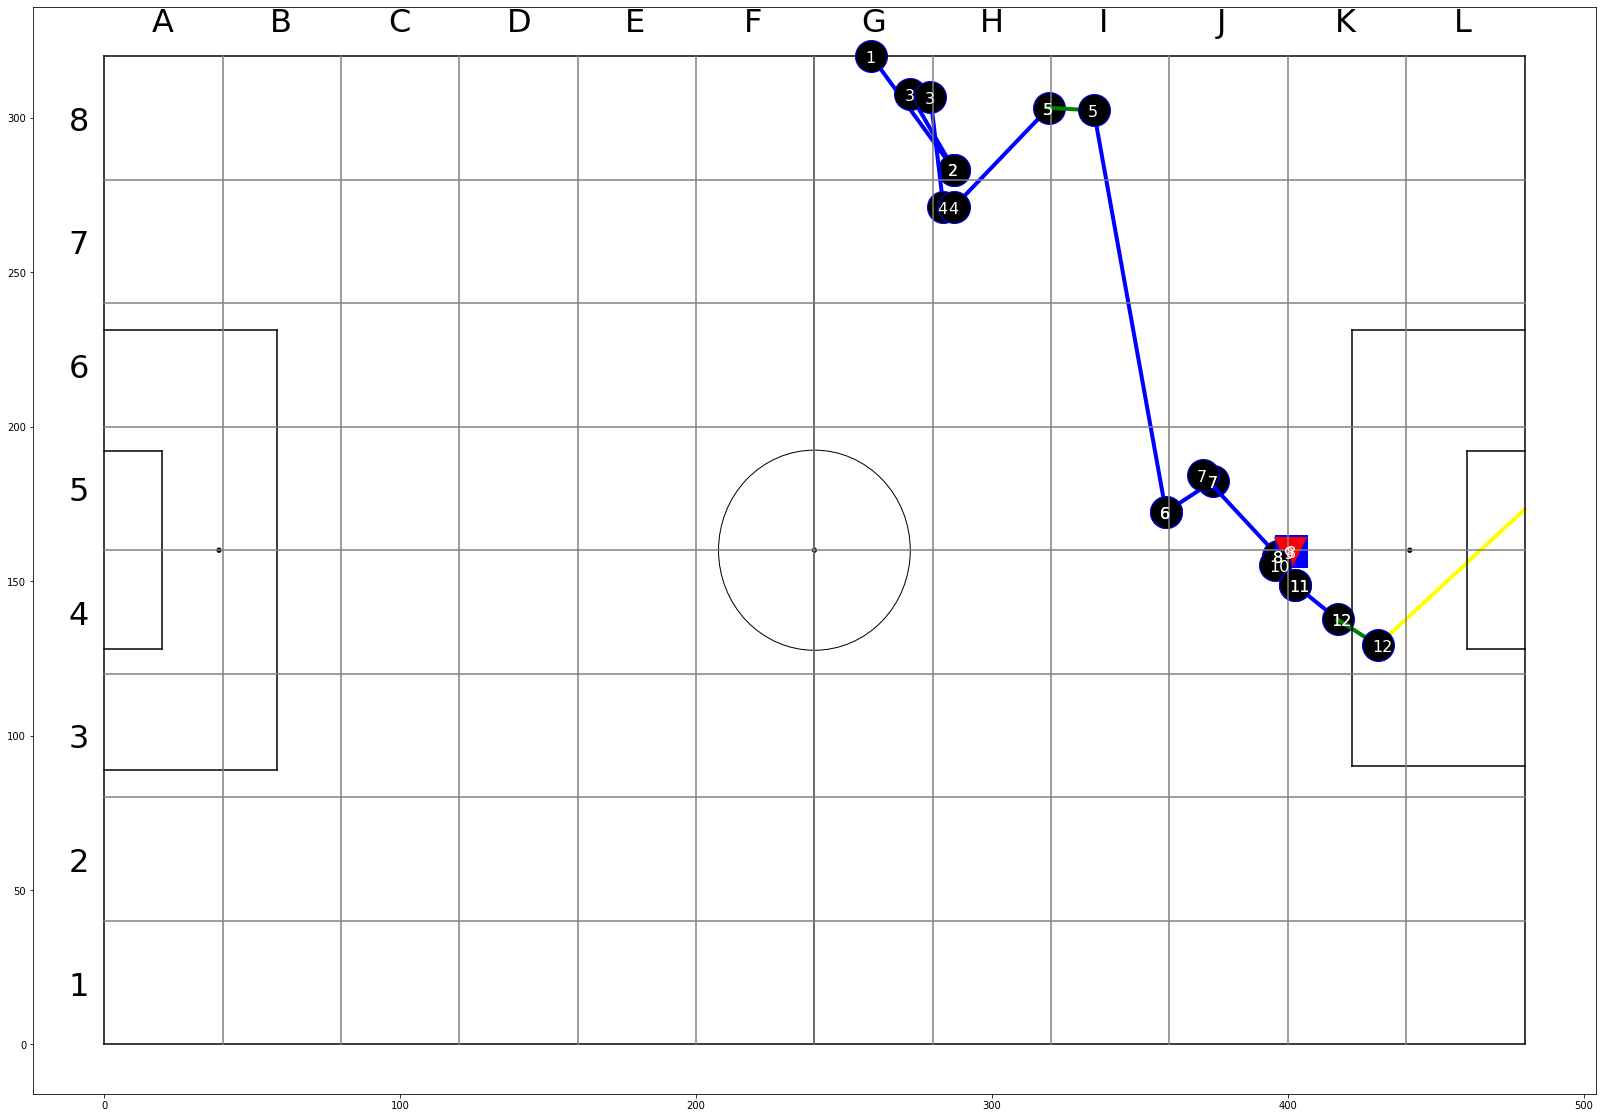

Sequence: 6
Team: Poland
1: Robert Lewandowski (Pass) <00:02:17.362>
2: Kamil Glik (Ball Receipt*) <00:02:19.016>
2: Kamil Glik (Pass) <00:02:21.722>
3: Jan Bednarek (Ball Receipt*) <00:02:23.028>
3: Jan Bednarek (Carry) <00:02:23.028>
3: Jan Bednarek (Pass) <00:02:25.583>
4: Kamil Glik (Ball Receipt*) <00:02:27.086>
4: Kamil Glik (Carry) <00:02:27.086>
4: Kamil Glik (Pass) <00:02:30.217>
5: Jan Bednarek (Ball Receipt*) <00:02:32.147>
5: Jan Bednarek (Carry) <00:02:32.147>
5: Jan Bednarek (Pass) <00:02:33.891>
6: Robert Lewandowski (Ball Receipt*) <00:02:36.609>


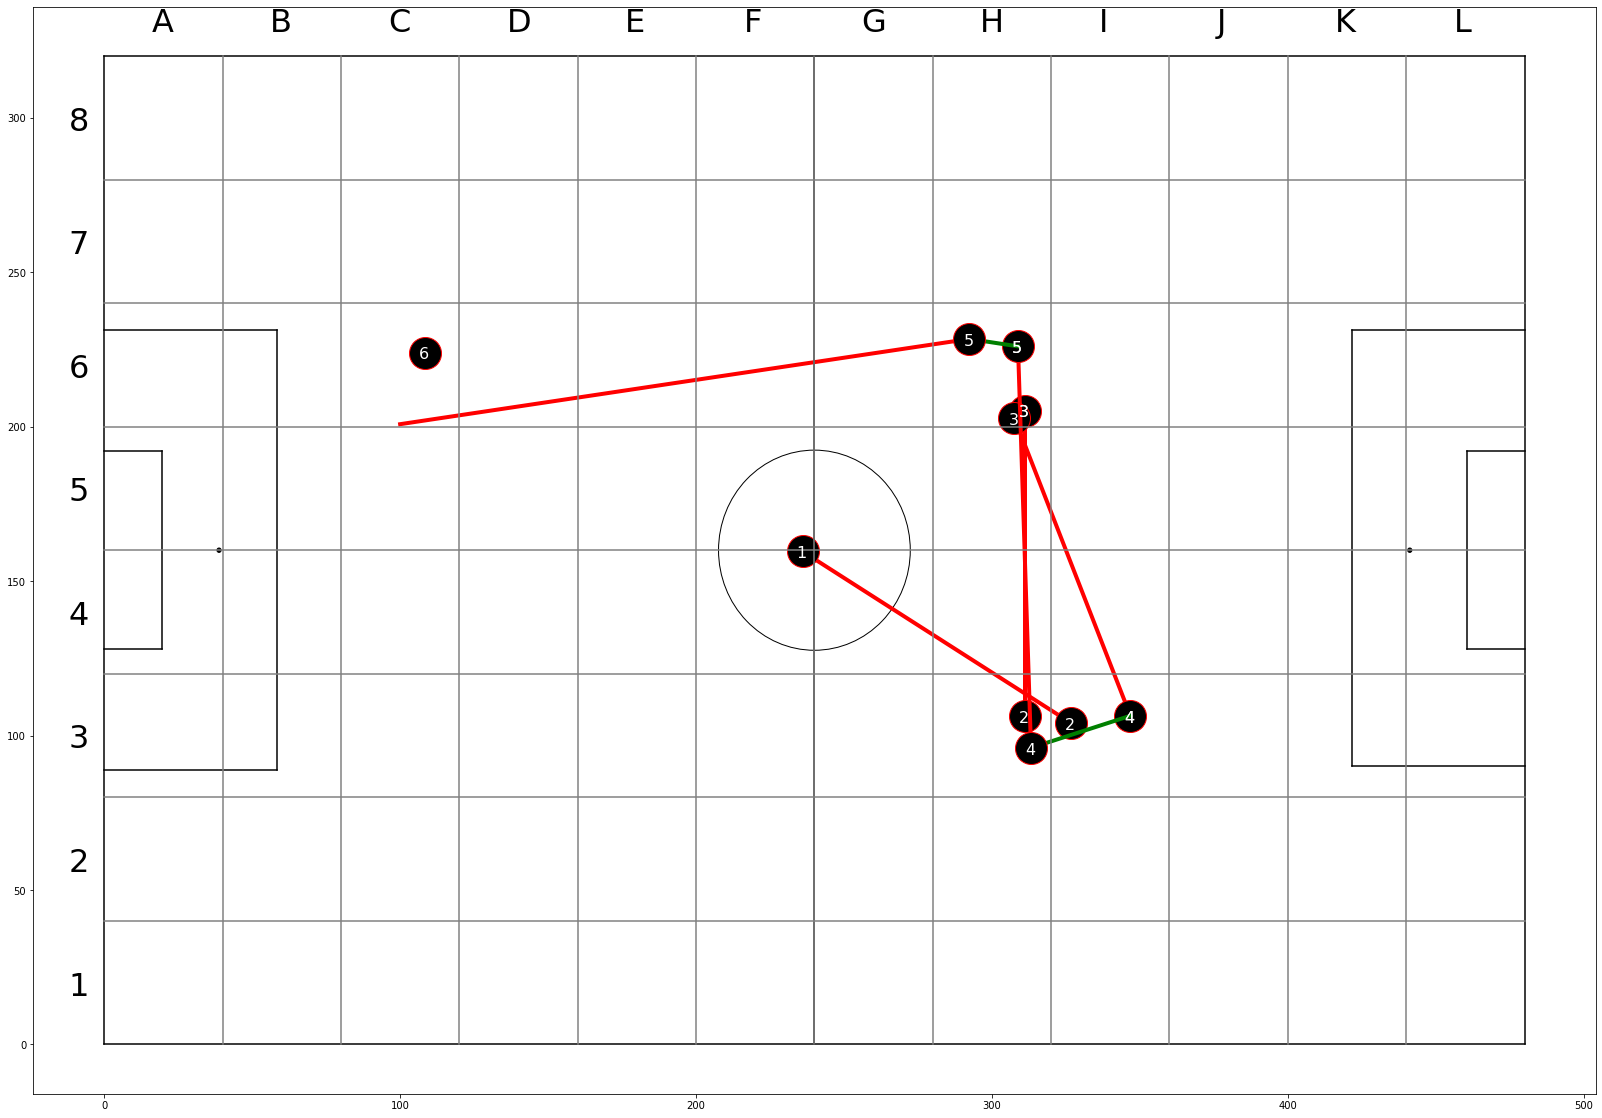

Sequence: 7
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:02:36.609>
2: Mikael Lustig (Ball Receipt*) <00:02:38.606>
2: Mikael Lustig (Carry) <00:02:38.606>
2: Mikael Lustig (Pass) <00:02:40.897>
3: Alexander Isak (Ball Receipt*) <00:02:43.264>
3: Alexander Isak (Duel) <00:02:43.264>
4: Kamil Glik (Pass) <00:02:43.264>
5: Mikael Lustig (Pass) <00:02:58.958>
6: Sebastian Larsson (Ball Receipt*) <00:03:00.252>
6: Sebastian Larsson (Carry) <00:03:00.252>
6: Sebastian Larsson (Pass) <00:03:00.268>
7: Mikael Lustig (Ball Receipt*) <00:03:01.146>
7: Mikael Lustig (Pass) <00:03:01.146>
8: Sebastian Larsson (Ball Receipt*) <00:03:01.294>
9: Piotr Zieliński (Block) <00:03:01.294>
10: Mikael Lustig (Pass) <00:03:11.677>
11: Kristoffer Olsson (Ball Receipt*) <00:03:12.556>
11: Kristoffer Olsson (Pass) <00:03:12.556>
12: Mikael Lustig (Ball Receipt*) <00:03:13.491>
12: Mikael Lustig (Pass) <00:03:13.491>
13: Robin Quaison (Ball Receipt*) <00:03:16.503>
14: Kamil Glik (Pass) <00:03:16.503>
15:

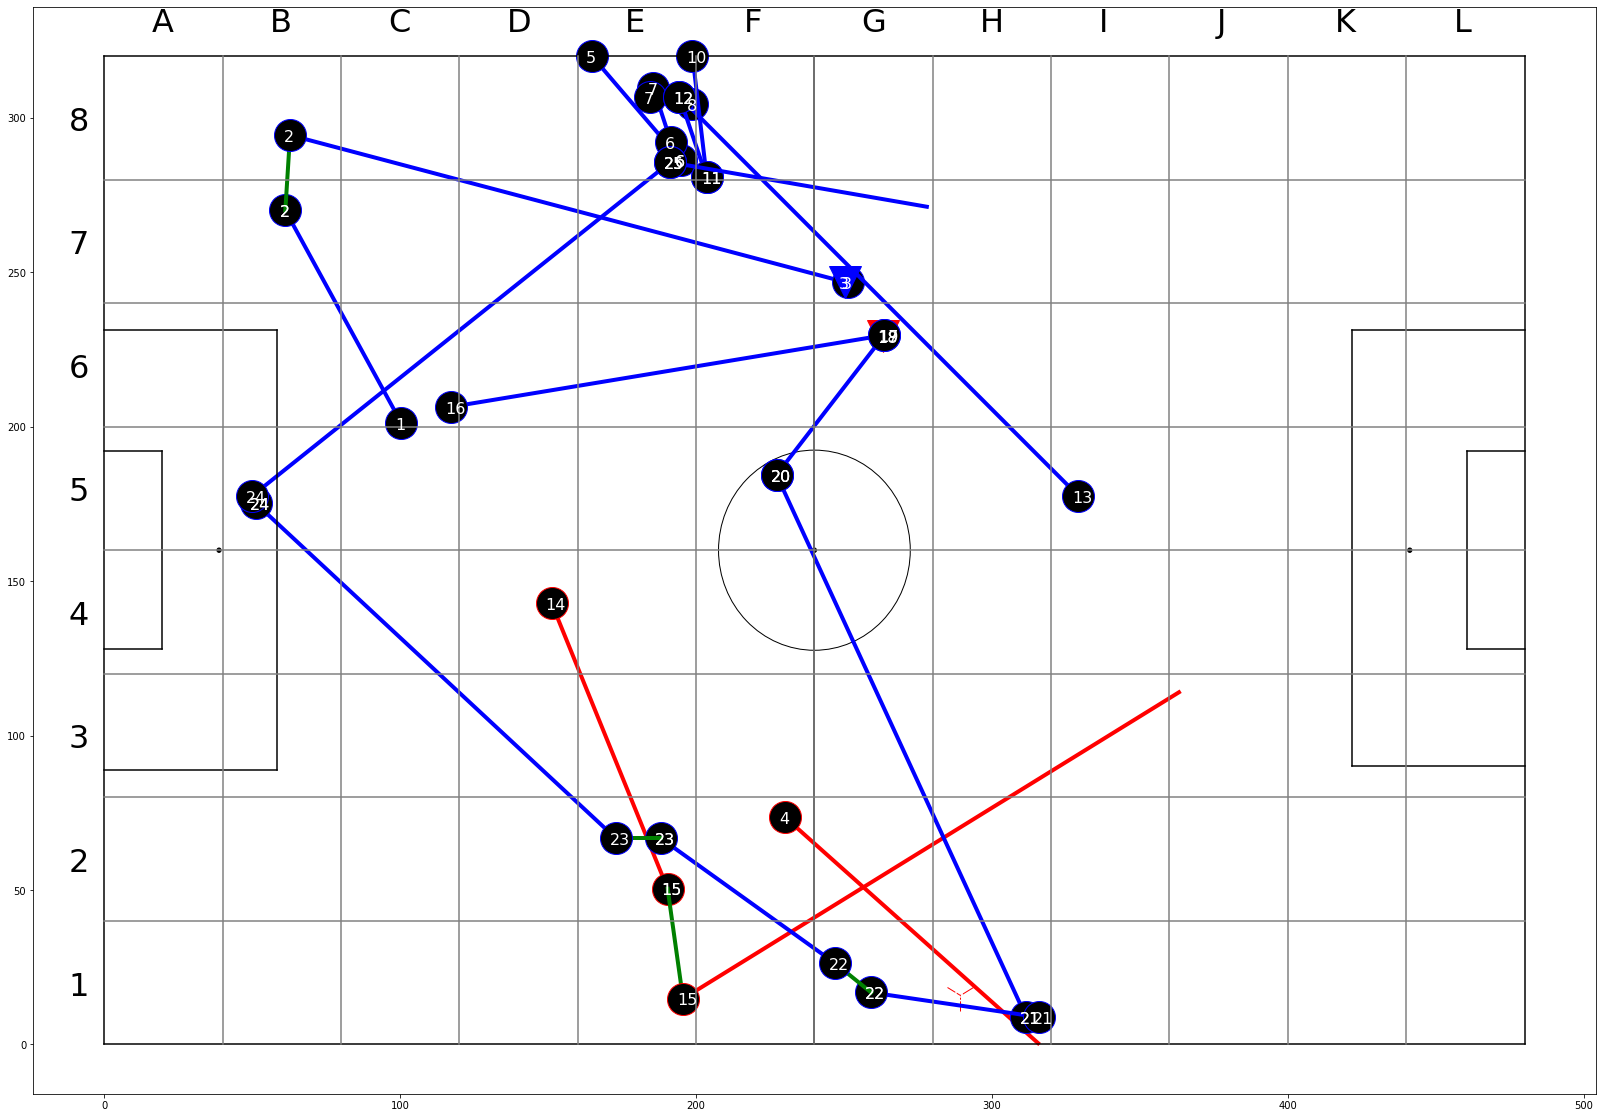

In [5]:
from draw.draw_sequences import draw_events_sequence

start_team = merged_events['possession_team'][0]

for i, s in enumerate(sequences):
    print(f'Sequence: {i+1}')
    draw_events_sequence(s, start_team, 12, 8, scale=4)
    if i == 6:
        break

In [6]:
sequences[3].to_csv('test1.csv')
sequences[4].to_csv('test2.csv')

## Analiza rozkładu wyprowadzanych podań

### Reset dataframe do jednolitej perspektywy

In [7]:
merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

### Tablica rozkładu podań Polski

In [8]:
from analysis.events_in_area import events_in_area

start_pass_areas_count = events_in_area(merged_events, 'Poland', 'Pass')

start_pass_areas_count[0:5]

/home/user/dev/sport-data-science/analysis/events_in_area.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[events_df['type'] == event]


[('A1', '0.88%'),
 ('A2', '0.18%'),
 ('A3', '0.35%'),
 ('A4', '0.71%'),
 ('A5', '0.71%')]

### Boisko z wypisanym rozkładem wyprowadzanych podań Polski w danej strefie

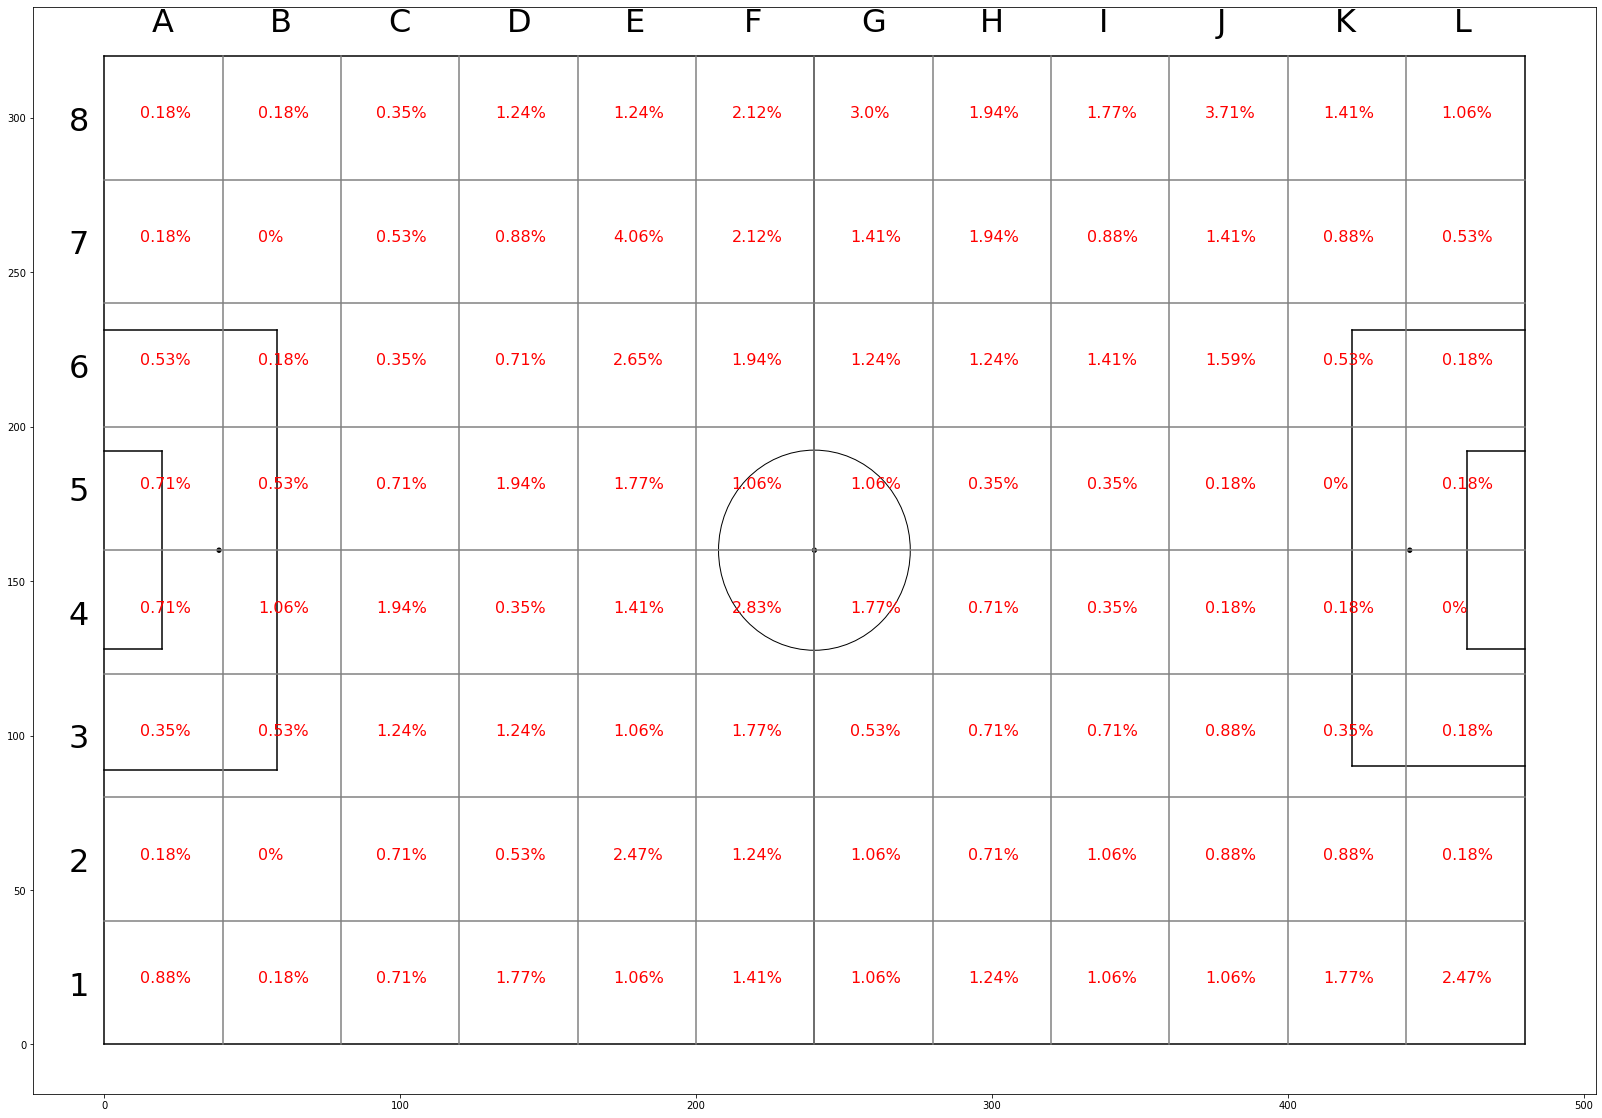

In [9]:
from draw.draw_areas_percents import draw_areas_percents

draw_areas_percents(start_pass_areas_count, 4)

### Wyprowadzane podania przez Polskę jako Mapa Ciepła

In [10]:
import pandas as pd

df_pass = merged_events.loc[(merged_events['type'] == 'Pass') & (merged_events['possession_team'] == 'Poland')]
location_xy = df_pass.location.apply(pd.Series)
location_xy.columns = ['x', 'y']
location_xy.head(5)

,x,y
8,24.8,42.0
10,33.6,42.6
13,40.8,34.5
16,50.0,18.7
19,38.1,12.3


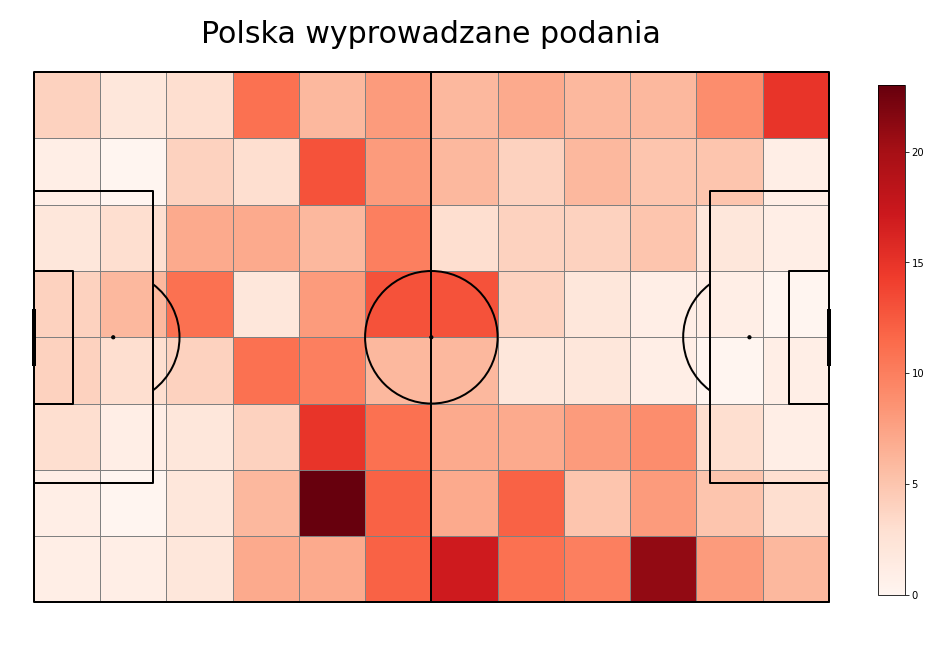

In [11]:
from mplsoccer.pitch import Pitch
import matplotlib.pyplot as plt

#plot vertical pitch
pitch = Pitch(line_zorder=2, line_color='black')
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)
#get the 2D histogram
bin_statistic = pitch.bin_statistic(location_xy.x, location_xy.y, statistic='count', bins=(12, 8), normalize=False)
#normalize by number of games
bin_statistic["statistic"] = bin_statistic["statistic"]
#make a heatmap
pcm  = pitch.heatmap(bin_statistic, cmap='Reds', edgecolor='grey', ax=ax['pitch'])
#legend to our plot
ax_cbar = fig.add_axes((1, 0.093, 0.03, 0.786))
cbar = plt.colorbar(pcm, cax=ax_cbar)
fig.suptitle('Polska wyprowadzane podania', fontsize = 30)
plt.show()

### Tablica rozkładu podań Szwecji

In [12]:
start_pass_areas_count = events_in_area(merged_events, 'Sweden', 'Pass')

start_pass_areas_count[0:5]

[('A1', '0%'),
 ('A2', '0.74%'),
 ('A3', '0.37%'),
 ('A4', '1.86%'),
 ('A5', '4.09%')]

### Wypisane rozkłady wyprowadzanych podań Szwecji

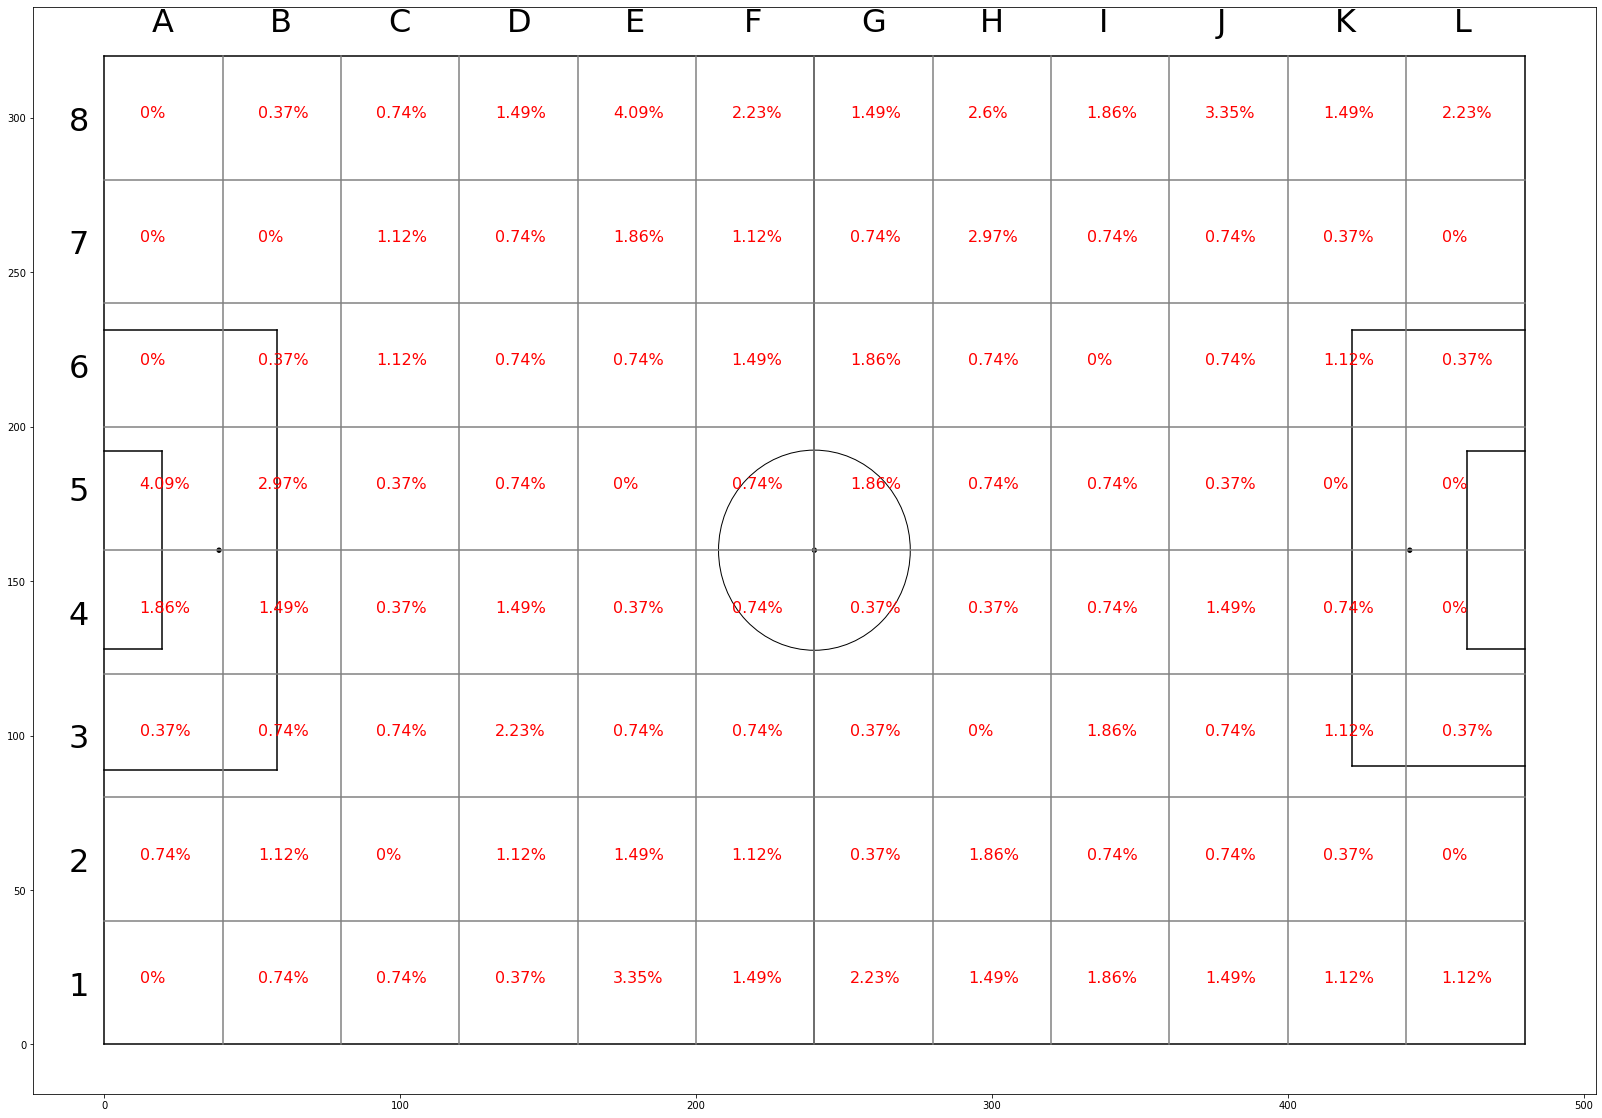

In [13]:
draw_areas_percents(start_pass_areas_count, 4)

### Wyprowadzane podania Szwecji - Mapa Ciepła

In [14]:
df_pass = merged_events.loc[(merged_events['type'] == 'Pass') & (merged_events['possession_team'] == 'Sweden')]
location_xy = df_pass.location.apply(pd.Series)
location_xy.columns = ['x', 'y']
location_xy.head(5)

,x,y
0,60.0,40.0
3,36.8,41.1
5,49.8,68.1
38,41.8,51.0
40,50.3,59.4


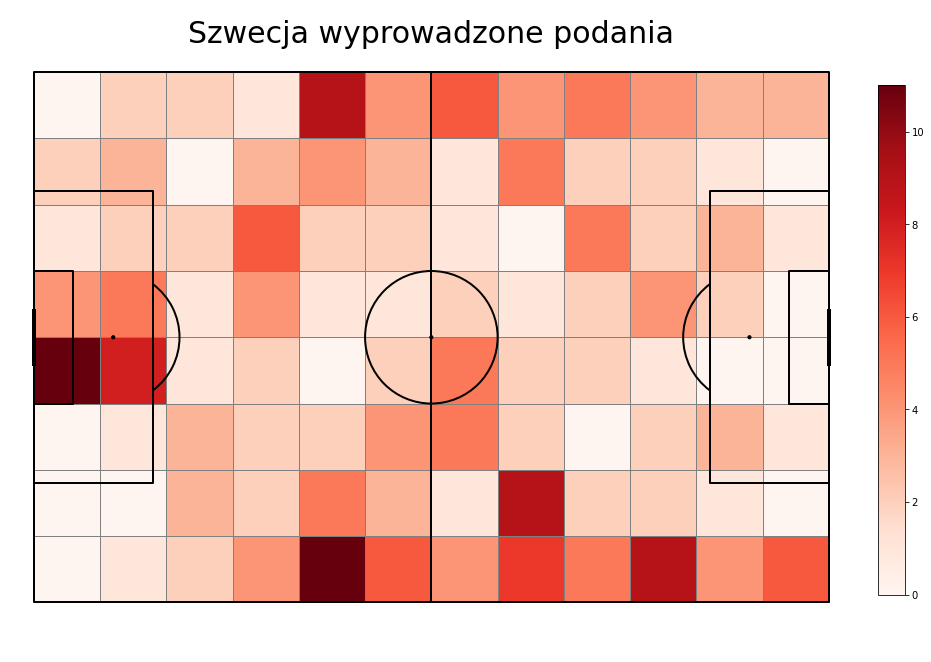

In [15]:
#plot vertical pitch
pitch = Pitch(line_zorder=2, line_color='black')
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)
#get the 2D histogram
bin_statistic = pitch.bin_statistic(location_xy.x, location_xy.y, statistic='count', bins=(12, 8), normalize=False)
#normalize by number of games
bin_statistic["statistic"] = bin_statistic["statistic"]
#make a heatmap
pcm  = pitch.heatmap(bin_statistic, cmap='Reds', edgecolor='grey', ax=ax['pitch'])
#legend to our plot
ax_cbar = fig.add_axes((1, 0.093, 0.03, 0.786))
cbar = plt.colorbar(pcm, cax=ax_cbar)
fig.suptitle('Szwecja wyprowadzone podania', fontsize = 30)
plt.show()

## Analiza rozkładu przyjmowanych podań

### Tablica rozkładu przyjęć - Polska

In [16]:
from analysis.events_in_area import events_in_area

end_pass_areas_count = events_in_area(merged_events, 'Poland', 'Ball Receipt*')

end_pass_areas_count[0:5]

[('A1', '0.21%'),
 ('A2', '0.21%'),
 ('A3', '0%'),
 ('A4', '0.21%'),
 ('A5', '0.42%')]

### Rysunek rozkładu przyjęć - Polska

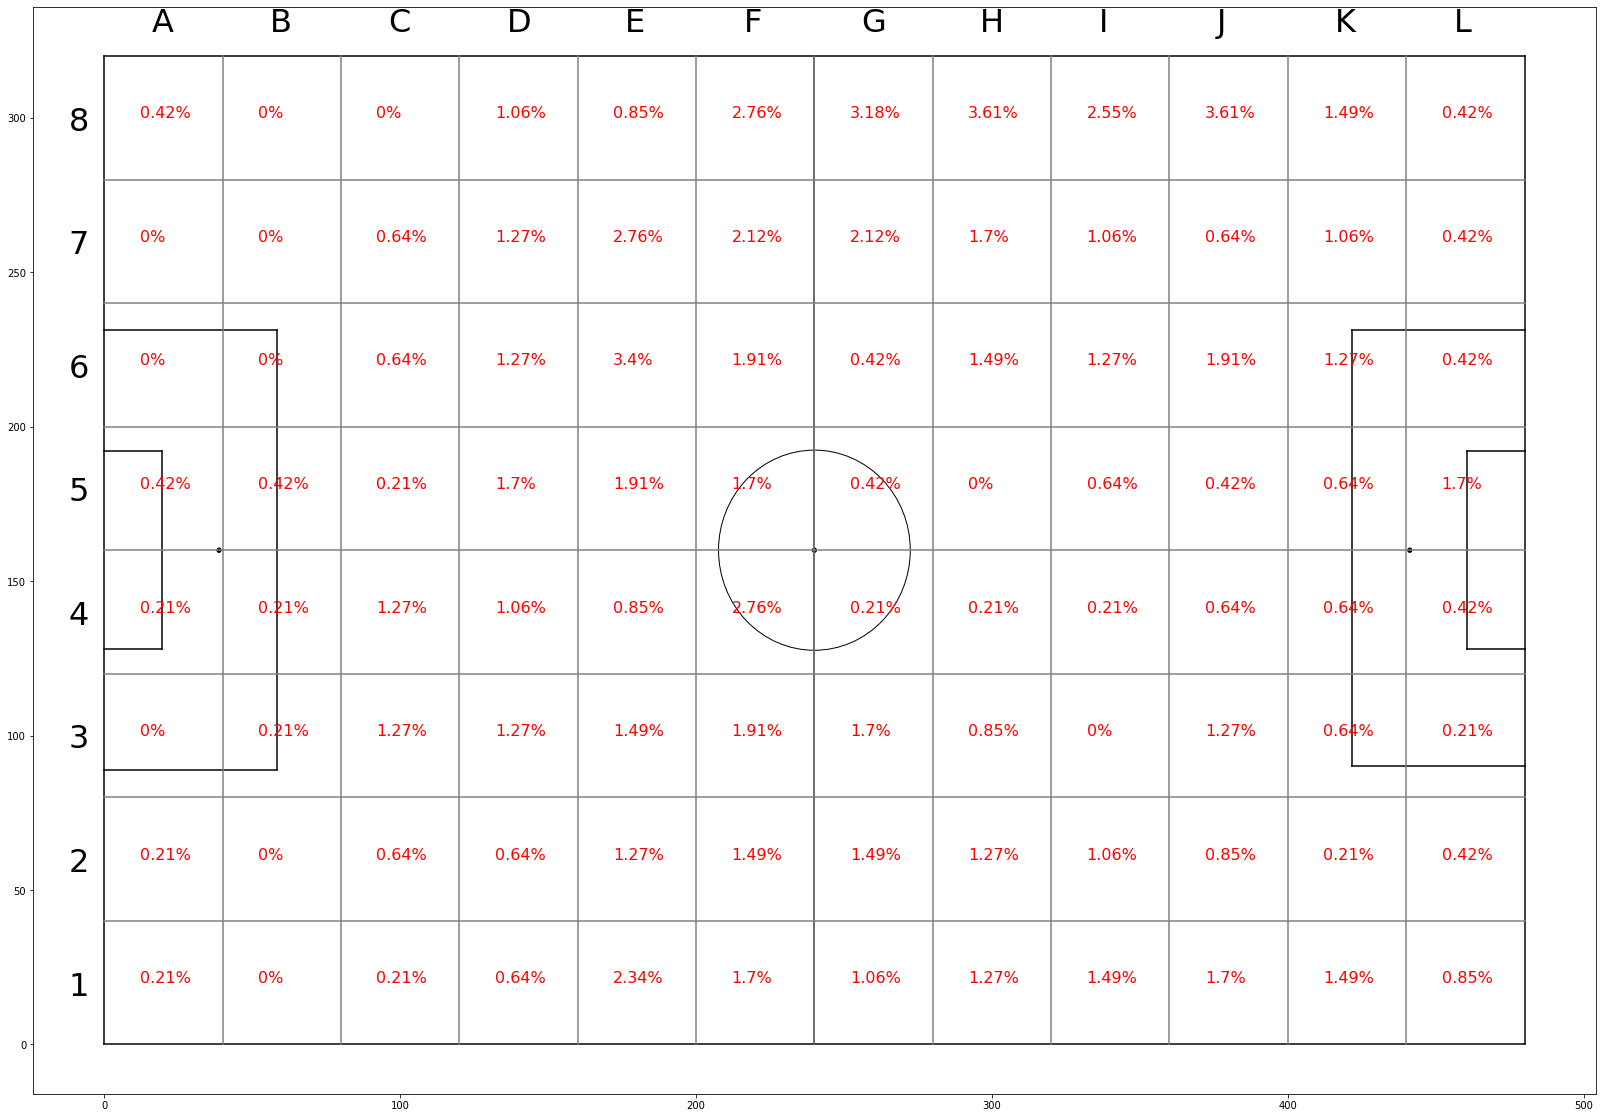

In [17]:
draw_areas_percents(end_pass_areas_count, 4)

### Mapa ciepła przyjęć - Polska

In [18]:
df_pass = merged_events.loc[(merged_events['type'] == 'Ball Receipt*') & (merged_events['possession_team'] == 'Poland')]
location_xy = df_pass.location.apply(pd.Series)
location_xy.columns = ['x', 'y']
location_xy.head(5)

,x,y
9,33.6,42.6
11,42.8,41.8
14,54.5,18.8
17,38.9,11.2
20,29.7,26.0


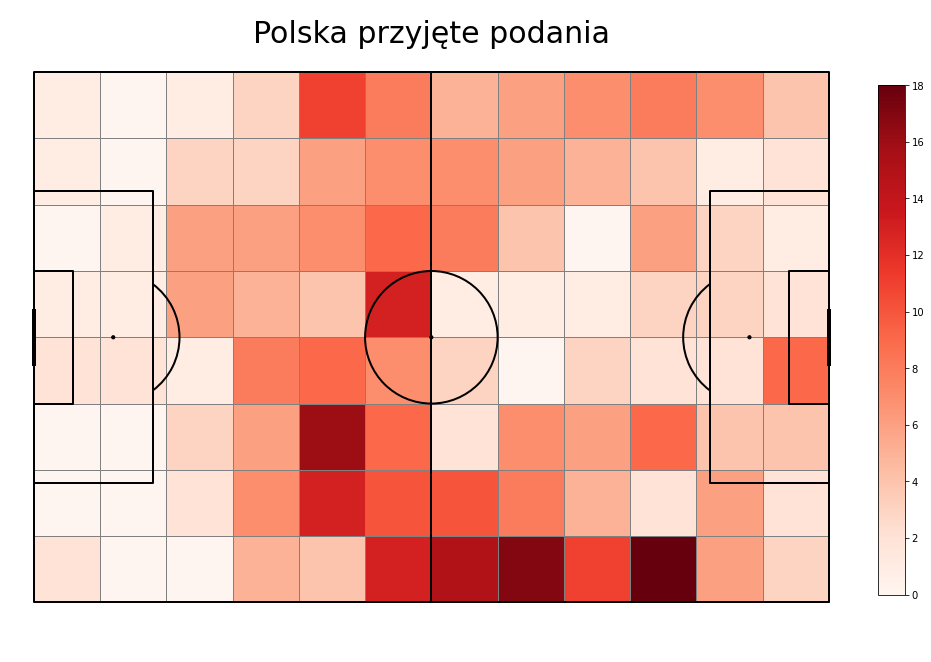

In [19]:
#plot vertical pitch
pitch = Pitch(line_zorder=2, line_color='black')
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)
#get the 2D histogram
bin_statistic = pitch.bin_statistic(location_xy.x, location_xy.y, statistic='count', bins=(12, 8), normalize=False)
#normalize by number of games
bin_statistic["statistic"] = bin_statistic["statistic"]
#make a heatmap
pcm  = pitch.heatmap(bin_statistic, cmap='Reds', edgecolor='grey', ax=ax['pitch'])
#legend to our plot
ax_cbar = fig.add_axes((1, 0.093, 0.03, 0.786))
cbar = plt.colorbar(pcm, cax=ax_cbar)
fig.suptitle('Polska przyjęte podania', fontsize = 30)
plt.show()

### Tablica rozkładu przyjęć - Szwecja

In [20]:
from analysis.events_in_area import events_in_area

end_pass_areas_count = events_in_area(merged_events, 'Sweden', 'Ball Receipt*')

end_pass_areas_count[0:5]

[('A1', '0%'), ('A2', '1.0%'), ('A3', '0%'), ('A4', '0.5%'), ('A5', '0.5%')]

### Rysunek rozkładu przyjęć - Szwecja

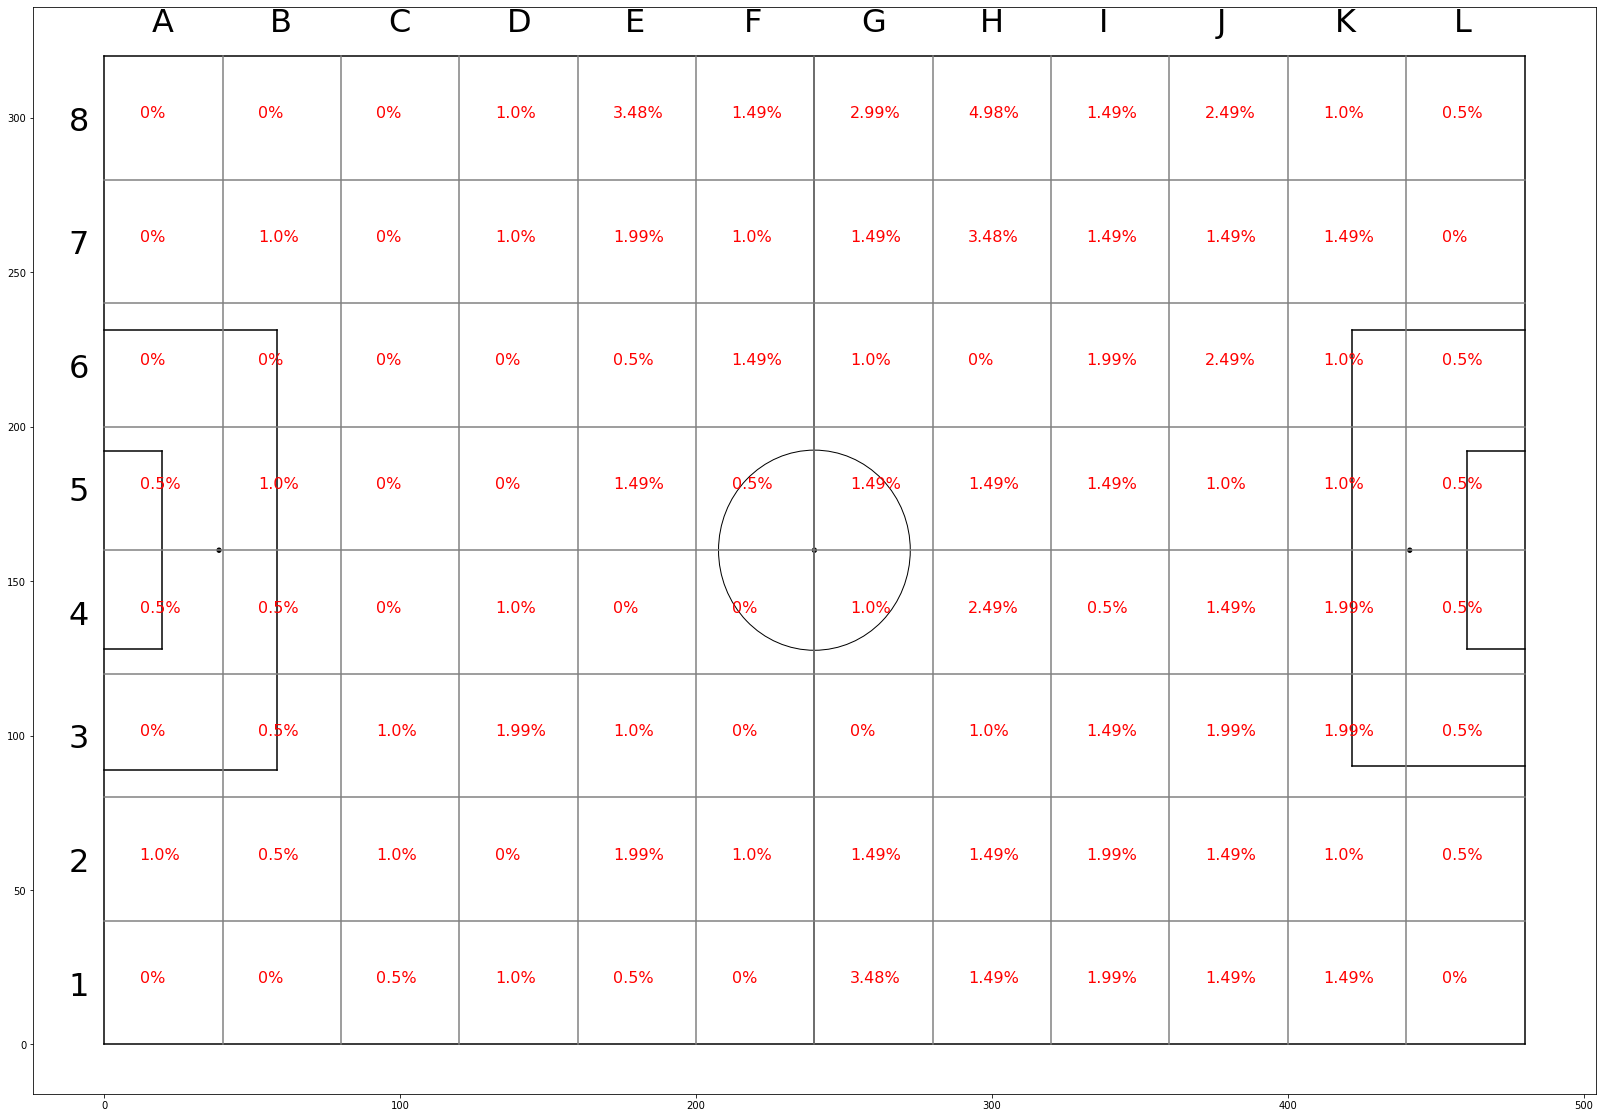

In [21]:
draw_areas_percents(end_pass_areas_count, 4)

### Mapa ciepła przyjęć - Szwecja

In [22]:
df_pass = merged_events.loc[(merged_events['type'] == 'Ball Receipt*') & (merged_events['possession_team'] == 'Sweden')]
location_xy = df_pass.location.apply(pd.Series)
location_xy.columns = ['x', 'y']
location_xy.head(5)

,x,y
1,36.1,39.7
4,49.8,68.1
6,95.3,38.1
39,50.3,59.4
41,39.5,69.9


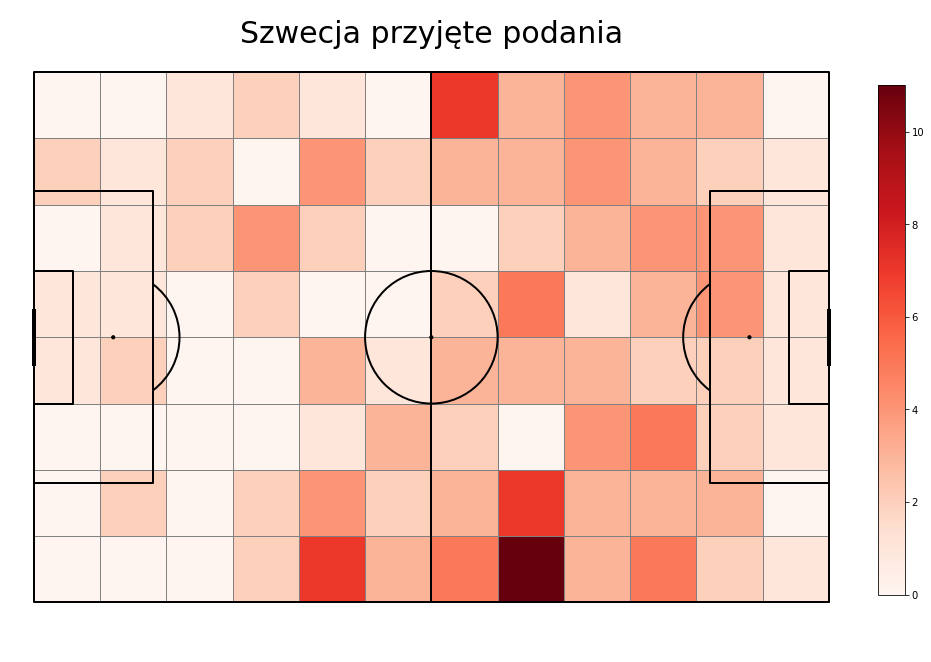

In [23]:
#plot vertical pitch
pitch = Pitch(line_zorder=2, line_color='black')
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)
#get the 2D histogram
bin_statistic = pitch.bin_statistic(location_xy.x, location_xy.y, statistic='count', bins=(12, 8), normalize=False)
#normalize by number of games
bin_statistic["statistic"] = bin_statistic["statistic"]
#make a heatmap
pcm  = pitch.heatmap(bin_statistic, cmap='Reds', edgecolor='grey', ax=ax['pitch'])
#legend to our plot
ax_cbar = fig.add_axes((1, 0.093, 0.03, 0.786))
cbar = plt.colorbar(pcm, cax=ax_cbar)
fig.suptitle('Szwecja przyjęte podania', fontsize = 30)
plt.show()